In [1]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict

/Users/jyoti/Documents/Learnings-Code-Projects/Agentic_ai/LangGraph-Learning/.venv/lib/python3.9/site-packages/langgraph/cache/base/__init__.py:8: LangChainPendingDeprecationWarning: The default value of `allowed_objects` will change in a future version. Pass an explicit value (e.g., allowed_objects='messages' or allowed_objects='core') to suppress this warning.
  from langgraph.checkpoint.serde.jsonplus import JsonPlusSerializer


In [8]:
## Define state
class BMIState(TypedDict):
    weight_kg: float
    height_m: float
    bmi: float
    category: str

In [3]:
def cal_bmi(state: BMIState) -> BMIState:
    weight=state['weight_kg']
    height=state['height_m']
    
    bmi=weight/(height**2)
    state['bmi']=round(bmi,2)
    
    return state

In [9]:
def bmi_category(state: BMIState) -> BMIState:
    
    bmi = state['bmi']
    
    if bmi < 18.5:
        state['category'] = 'Underweight'
    elif 18.5 <= bmi < 24.9:
        state['category'] = 'Normal weight'
    elif 25 <= bmi < 29.9:
        state['category'] = 'Overweight'
    else:
        state['category'] = 'Obesity'
        
    return state

In [10]:
## Define graph
graph = StateGraph(BMIState)

# add nodes to the graph
graph.add_node('calculate_bmi', cal_bmi)
graph.add_node('check_bmi_category', bmi_category)

## add edges to the graph
graph.add_edge(START, 'calculate_bmi')
graph.add_edge('calculate_bmi', 'check_bmi_category')
graph.add_edge('check_bmi_category', END)

# compile the graph
workflow = graph.compile()

In [12]:
## execute the graph
initial_state = {'weight_kg':80, 'height_m':1.75}
final_state = workflow.invoke(initial_state)
print(final_state)

{'weight_kg': 80, 'height_m': 1.75, 'bmi': 26.12, 'category': 'Overweight'}


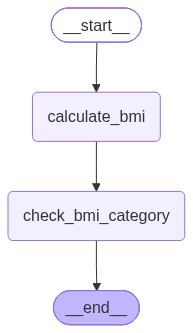

In [11]:
## Display workflow graph

from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())